# 05 — Recurrent Neural Networks (LSTM, GRU)

**Input:** `../data/processed/raddar.npz`, shared code `../src/dl_utils.py`, previous results `../results/dl_results_all.csv`
**Output:** results in `../results/`, figures in `../figures/`

**Why an RNN?** A recurrent network reads its input **as a sequence**, one step at a time, and keeps a **memory** (hidden state) of what it has already seen. A radar map is not naturally a sequence, but it can be read as one — exactly like the course example that reads an MNIST image as a sequence of pixel columns.

**Two reading directions**
| Reading | Sequence length | One step = | What the network must learn |
|---|---|---|---|
| **Along Doppler** | 61 steps | one column: the 11 range bins at one velocity | how the energy evolves across velocities (micro-Doppler spread, signature width) |
| **Along range** | 11 steps | one row: the 61 Doppler bins at one distance | how the signature evolves with distance (extent of the target in range) |

**Models compared:** LSTM (both directions), bidirectional LSTM and GRU (along Doppler).

**Hypothesis (H5):** the RNN works, but less well than the CNN (0.941): it is designed for ordered sequences, while a radar map is a 2D image in which both axes matter together. Reading along Doppler should beat reading along range, since the micro-Doppler spread is the key feature.

Same protocol as before: 3 seeds, early stopping on the validation sessions, single evaluation on the test sessions, and the full vs cropped map comparison (stripe shortcut).

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../src")
from dl_utils import load_data, crop_center, normalise, evaluate, plot_history, plot_confusion, CENTER_DOPPLER

import keras
from keras import layers

SEEDS = [42, 7, 2026]
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

D = load_data()
X, y, CLASSES = D["X"], D["y"], D["class_names"]
tr, va, te = D["train"], D["val"], D["test"]
Xn = normalise(X, tr)                       # (N, 11 range, 61 Doppler)
Xc = normalise(crop_center(X), tr)          # (N, 11, 13)

# An RNN expects (samples, time steps, features per step)
SEQ = {
    "full, along Doppler": Xn.transpose(0, 2, 1),   # 61 steps of 11 values
    "full, along range": Xn,                        # 11 steps of 61 values
    "cropped, along Doppler": Xc.transpose(0, 2, 1) # 13 steps of 11 values
}
for k, v in SEQ.items():
    print(f"{k:24s} -> {v.shape[1]} steps x {v.shape[2]} features")

I0000 00:00:1794320094.889855     827 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794320094.928568     827 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794320095.903542     827 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


full, along Doppler      -> 61 steps x 11 features
full, along range        -> 11 steps x 61 features
cropped, along Doppler   -> 13 steps x 11 features


## 1. Architectures
**LSTM (Long Short-Term Memory).** At each step t the LSTM receives one column (or row) x_t and updates two memories:
- a **cell state** (long-term memory), modified through three **gates** (small sigmoid layers between 0 and 1): the **forget gate** decides what to erase, the **input gate** what to write, the **output gate** what to output now;
- a **hidden state** h_t (the current summary of the sequence).

The gates solve the *vanishing gradient* problem of a simple RNN, so the network can keep information over long sequences. After the last step, h_T summarises the whole map and goes to the classifier.

**GRU (Gated Recurrent Unit):** a simplified LSTM with 2 gates and no separate cell state — fewer parameters, often similar results.

**Bidirectional LSTM:** two LSTMs, one reading left → right and one right → left; their final states are concatenated. Along Doppler there is no natural "before" and "after" between velocities, so reading in both directions is natural.

```
Input (steps × features) → [LSTM | GRU | Bidirectional LSTM](64 units) → Dropout(0.3) → Dense(64, ReLU) → Dropout(0.3) → Dense(3, softmax)
```

In [2]:
def build_rnn(input_shape, kind="LSTM", units=64, dropout=0.3, n_classes=3):
    inp = keras.Input(input_shape)
    if kind == "LSTM":
        x = layers.LSTM(units, name="rnn")(inp)
    elif kind == "GRU":
        x = layers.GRU(units, name="rnn")(inp)
    elif kind == "BiLSTM":
        x = layers.Bidirectional(layers.LSTM(units), name="rnn")(inp)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out, name=kind)

def train(model, Xi, seed, epochs=100):
    keras.utils.set_random_seed(seed)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(Xi[tr], y[tr], validation_data=(Xi[va], y[va]), epochs=epochs, batch_size=128,
                  callbacks=[stop], verbose=0)
    return h, time.time() - t0

for kind in ["LSTM", "GRU", "BiLSTM"]:
    print(f"{kind:7s} along Doppler: {build_rnn(SEQ['full, along Doppler'].shape[1:], kind).count_params():,} parameters")
build_rnn(SEQ["full, along Doppler"].shape[1:], "LSTM").summary()

LSTM    along Doppler: 23,811 parameters
GRU     along Doppler: 19,139 parameters
BiLSTM  along Doppler: 47,363 parameters


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 61, 11)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rnn (LSTM)                      │ (None, 64)             │        19,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,811 (93.01 KB)

 Trainable params: 23,811 (93.01 KB)

 Non-trainable params: 0 (0.00 B)

## 2. Training
| Experiment | Model | Reading | Question |
|---|---|---|---|
| A | LSTM | full map, along Doppler | baseline RNN |
| B | LSTM | full map, along range | which axis carries the information as a sequence? |
| C | Bidirectional LSTM | full map, along Doppler | does reading both ways help? |
| D | GRU | full map, along Doppler | simpler gated cell |
| E | LSTM | cropped map, along Doppler | stripe shortcut test |

Each experiment is trained with 3 seeds.

In [3]:
EXPERIMENTS = [
    ("LSTM", "full, along Doppler"),
    ("LSTM", "full, along range"),
    ("BiLSTM", "full, along Doppler"),
    ("GRU", "full, along Doppler"),
    ("LSTM", "cropped, along Doppler"),
]
runs, histories, preds, models = [], {}, {}, {}
for kind, inp in EXPERIMENTS:
    Xi = SEQ[inp]
    for s in SEEDS:
        keras.utils.set_random_seed(s)
        model = build_rnn(Xi.shape[1:], kind)
        h, t = train(model, Xi, s)
        pv = model.predict(Xi[va], verbose=0).argmax(1)
        pt = model.predict(Xi[te], verbose=0).argmax(1)
        r = {"Model": kind, "Input": inp, "Seed": s, "Epochs": len(h.history["loss"]),
             "Best epoch": int(np.argmin(h.history["val_loss"])) + 1, "Time (s)": t,
             "Params": model.count_params(), "Val accuracy": (pv == y[va]).mean()}
        r.update({("Test " + k): v for k, v in evaluate(y[te], pt, CLASSES).items()})
        runs.append(r)
        if s == SEEDS[0]:
            histories[(kind, inp)], preds[(kind, inp)], models[(kind, inp)] = h, pt, model
        print(f"{kind:7s} | {inp:24s} | seed {s:4d} | test acc {r['Test accuracy']:.3f} | {t:5.0f} s")

runs = pd.DataFrame(runs)
runs.to_csv(RES / "dl_step5_rnn_runs.csv", index=False)

LSTM    | full, along Doppler      | seed   42 | test acc 0.892 |    49 s


LSTM    | full, along Doppler      | seed    7 | test acc 0.921 |    54 s


LSTM    | full, along Doppler      | seed 2026 | test acc 0.921 |    47 s


LSTM    | full, along range        | seed   42 | test acc 0.911 |    16 s


LSTM    | full, along range        | seed    7 | test acc 0.923 |    18 s


LSTM    | full, along range        | seed 2026 | test acc 0.922 |    17 s


... (5 outputs left out)

GRU     | full, along Doppler      | seed 2026 | test acc 0.928 |    75 s


LSTM    | cropped, along Doppler   | seed   42 | test acc 0.925 |    27 s


LSTM    | cropped, along Doppler   | seed    7 | test acc 0.920 |    22 s


LSTM    | cropped, along Doppler   | seed 2026 | test acc 0.928 |    17 s


In [4]:
cols = ["Val accuracy", "Test accuracy"] + [f"Test recall {c}" for c in CLASSES]
agg = runs.groupby(["Model", "Input"], sort=False)
summary = agg[cols].mean()
summary["Test accuracy std (3 seeds)"] = agg["Test accuracy"].std()
summary["Params"] = agg["Params"].first()
summary["Mean time per run (s)"] = agg["Time (s)"].mean()
summary.round(3)

Val accuracy  Test accuracy  Test recall Cars  \
Model  Input                                                                   
LSTM   full, along Doppler            0.925          0.911             0.887   
       full, along range              0.915          0.919             0.905   
BiLSTM full, along Doppler            0.931          0.931             0.917   
GRU    full, along Doppler            0.935          0.920             0.889   
LSTM   cropped, along Doppler         0.934          0.925             0.870   

                               Test recall Drones  Test recall People  \
Model  Input                                                            
LSTM   full, along Doppler                  0.926               0.921   
       full, along range                    0.897               0.947   
BiLSTM full, along Doppler                  0.941               0.936   
GRU    full, along Doppler                  0.949               0.926   
LSTM   cropped, along Doppler               0.934               0.965   

                               Test accuracy std (3 seeds)  Params  \
Model  Input                                                         
LSTM   full, along Doppler                           0.017   23811   
       full, along range                             0.007   36611   
BiLSTM full, along Doppler                           0.011   47363   
GRU    full, along Doppler                           0.019   19139   
LSTM   cropped, along Doppler                        0.004   23811   

                               Mean time per run (s)  
Model  Input                                          
LSTM   full, along Doppler                    50.024  
       full, along range                      16.954  
BiLSTM full, along Doppler                    74.355  
GRU    full, along Doppler                    76.590  
LSTM   cropped, along Doppler                 22.088

## 3. Learning curves (seed 42)

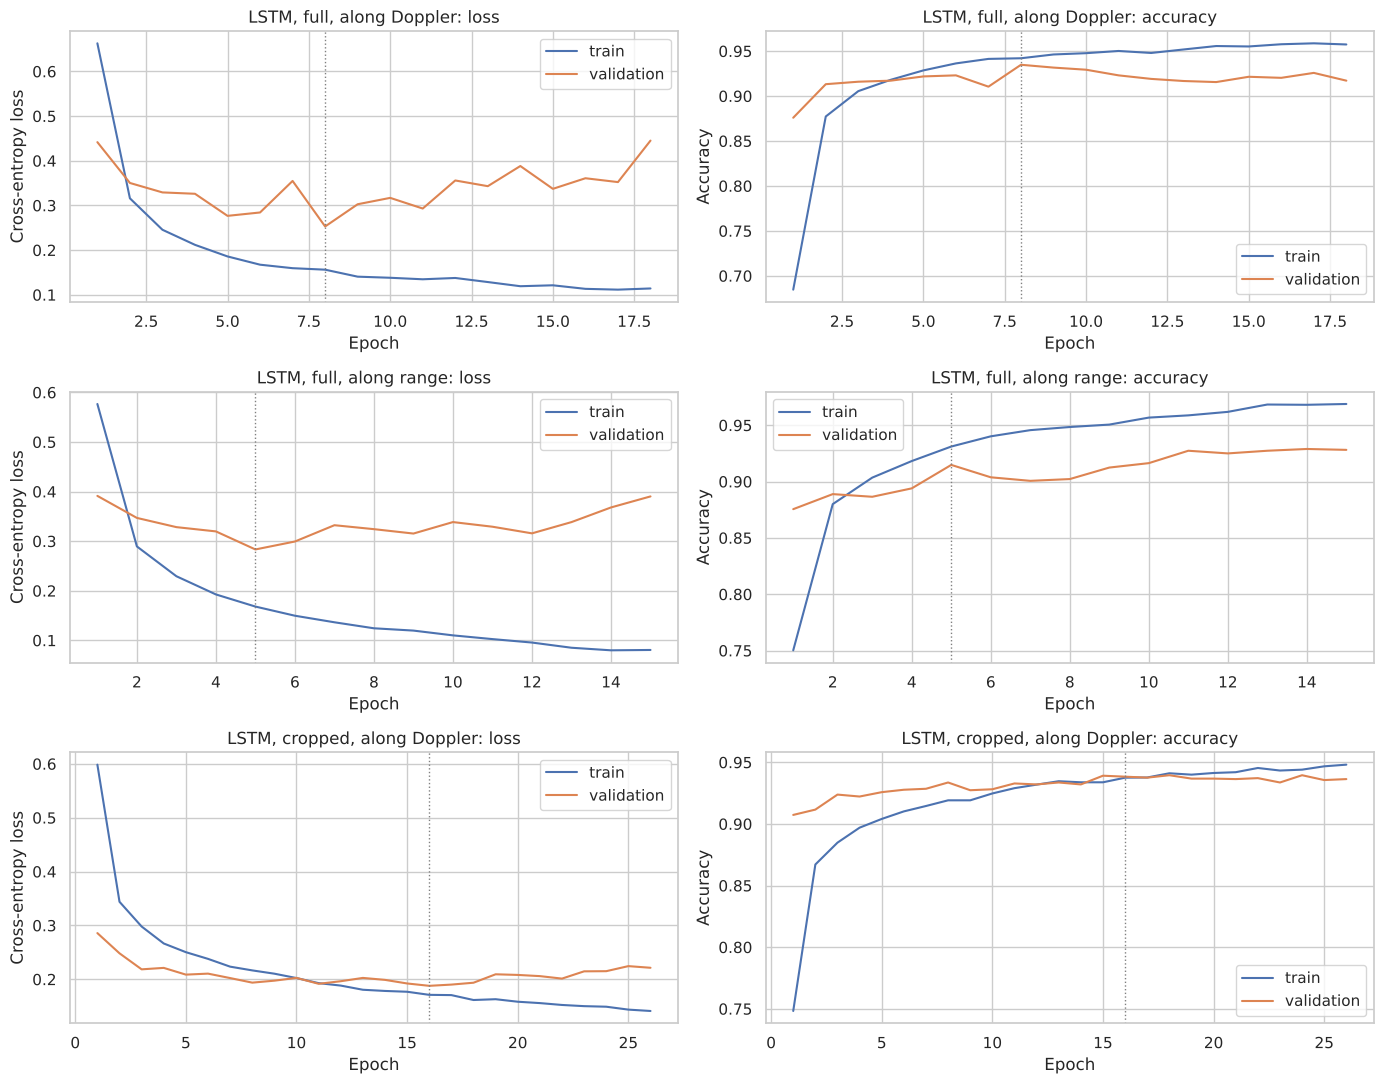

In [5]:
show = [("LSTM", "full, along Doppler"), ("LSTM", "full, along range"), ("LSTM", "cropped, along Doppler")]
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
for row, key in enumerate(show):
    plot_history(histories[key], f"{key[0]}, {key[1]}", axes[row, 0], axes[row, 1])
plt.tight_layout(); plt.savefig(FIG / "dl_17_rnn_learning_curves.png", dpi=200); plt.show()

## 4. Comparison with all previous models (test sessions)

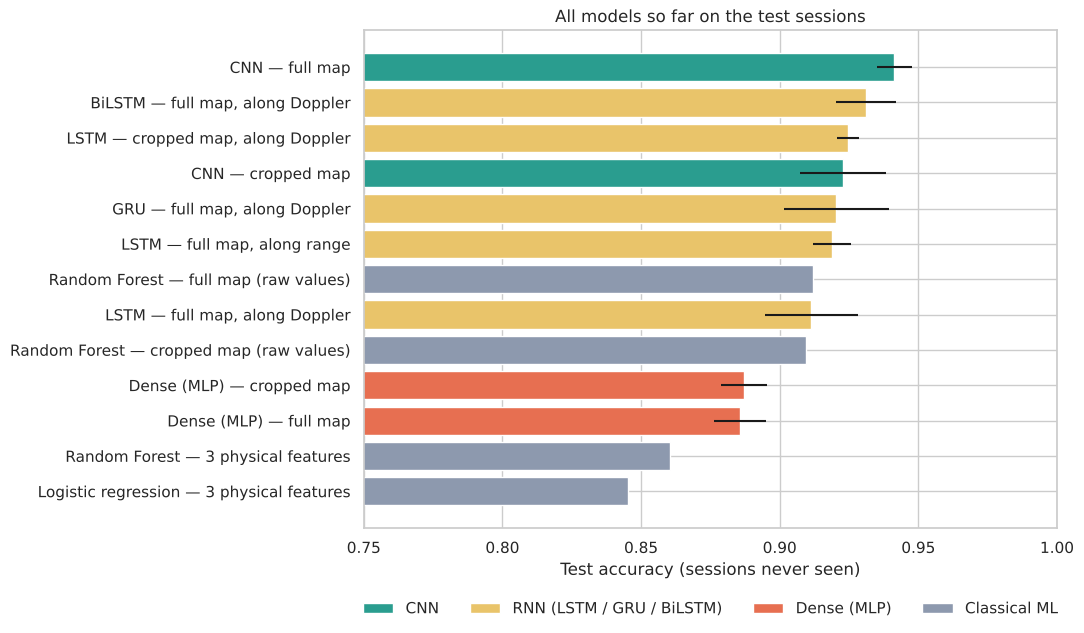

,Model,Input,Val accuracy,Test accuracy,Test recall Cars,Test recall Drones,Test recall People,Test accuracy std (3 seeds),Params
0,Logistic regression,3 physical features,0.916,0.845,0.681,0.899,0.947,NaN,NaN
1,Random Forest,3 physical features,0.916,0.861,0.759,0.842,0.962,NaN,NaN
2,Random Forest,full map (raw values),0.917,0.912,0.849,0.960,0.930,NaN,NaN
3,Random Forest,cropped map (raw values),0.918,0.909,0.837,0.954,0.938,NaN,NaN
4,Dense (MLP),full map,0.927,0.886,0.824,0.911,0.920,0.009,205315.0
5,Dense (MLP),cropped map,0.921,0.887,0.798,0.908,0.948,0.008,70147.0
6,CNN,full map,0.945,0.941,0.938,0.898,0.977,0.006,60739.0
7,CNN,cropped map,0.938,0.923,0.822,0.965,0.978,0.015,60739.0
8,LSTM,"full map, along Doppler",0.925,0.911,0.887,0.926,0.921,0.017,23811.0
9,LSTM,"full map, along range",0.915,0.919,0.905,0.897,0.947,0.007,36611.0


In [6]:
prev = pd.read_csv(RES / "dl_results_all.csv")
prev = prev[~prev["Model"].isin(["LSTM", "GRU", "BiLSTM"])]          # avoid duplicates if re-run
new = summary.reset_index()[["Model", "Input"] + cols + ["Test accuracy std (3 seeds)", "Params"]]
new["Input"] = new["Input"].str.replace("full, ", "full map, ").str.replace("cropped, ", "cropped map, ")
allres = pd.concat([prev, new], ignore_index=True)
allres.to_csv(RES / "dl_results_all.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 6.5))
lab = allres["Model"] + " — " + allres["Input"]
order = allres["Test accuracy"].sort_values().index
colours = {"CNN": "#2a9d8f", "Dense (MLP)": "#e76f51", "LSTM": "#e9c46a", "GRU": "#e9c46a", "BiLSTM": "#e9c46a"}
ax.barh(lab[order], allres.loc[order, "Test accuracy"],
        xerr=allres.loc[order, "Test accuracy std (3 seeds)"].fillna(0),
        color=[colours.get(m, "#8d99ae") for m in allres.loc[order, "Model"]])
ax.set(xlabel="Test accuracy (sessions never seen)", xlim=(0.75, 1.0), title="All models so far on the test sessions")
for m, c in [("CNN", "#2a9d8f"), ("RNN (LSTM / GRU / BiLSTM)", "#e9c46a"), ("Dense (MLP)", "#e76f51"), ("Classical ML", "#8d99ae")]:
    ax.barh(0, 0, color=c, label=m)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "dl_18_models_comparison.png", dpi=200); plt.show()
allres.round(3)

## 5. Confusion matrices (seed 42)

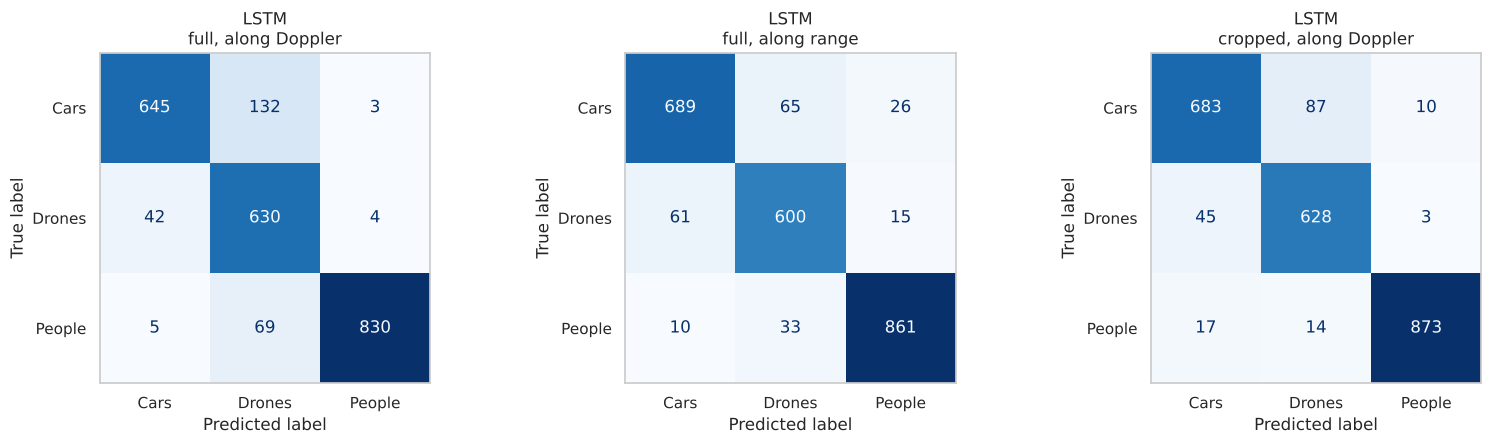

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, key in zip(axes, show):
    plot_confusion(y[te], preds[key], CLASSES, f"{key[0]}\n{key[1]}", ax)
plt.tight_layout(); plt.savefig(FIG / "dl_19_rnn_confusion.png", dpi=200); plt.show()

## 6. Which velocities does the LSTM use? (occlusion test)
For the LSTM reading the full map along Doppler, each Doppler column is **hidden** in turn (replaced by 0, the mean of the normalised data, i.e. a typical noise level), and we measure how much the predicted probability of the true class drops. A large drop means the LSTM relies on that velocity.

This is a model-agnostic alternative to Grad-CAM (which needs convolution layers). We separate **People with a stripe** and **People without a stripe** to check whether the LSTM, like the CNN, relies on the stripes.

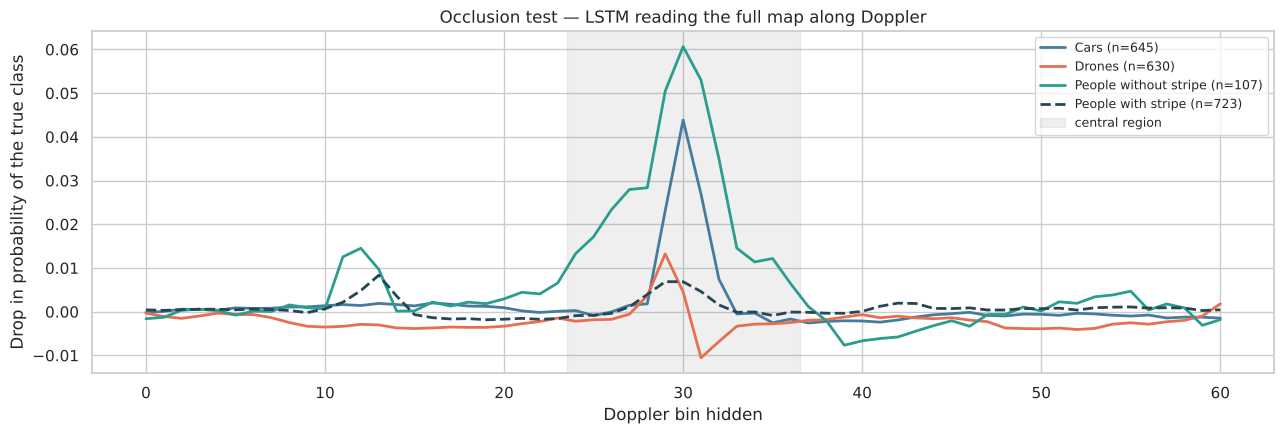

Share of the total probability drop caused by Doppler bins OUTSIDE the centre:
Cars                     0.323
Drones                   0.432
People without stripe    0.356
People with stripe       0.652


In [8]:
m = models[("LSTM", "full, along Doppler")]
Xs = SEQ["full, along Doppler"]
ok = te[preds[("LSTM", "full, along Doppler")] == y[te]]
base = m.predict(Xs[ok], verbose=0)[np.arange(len(ok)), y[ok]]
drop = np.zeros((len(ok), 61), dtype=np.float32)
for j in range(61):
    Xo = Xs[ok].copy(); Xo[:, j, :] = 0.0
    drop[:, j] = base - m.predict(Xo, verbose=0, batch_size=512)[np.arange(len(ok)), y[ok]]

noise = np.median(X.reshape(len(X), -1), axis=1)
stripe = ((X.min(axis=1) - noise[:, None])[:, np.r_[0:24, 37:61]] > 10).any(axis=1)
groups = {"Cars": (y[ok] == 0), "Drones": (y[ok] == 1),
          "People without stripe": (y[ok] == 2) & ~stripe[ok], "People with stripe": (y[ok] == 2) & stripe[ok]}
col = {"Cars": "#457b9d", "Drones": "#e76f51", "People without stripe": "#2a9d8f", "People with stripe": "#264653"}

fig, ax = plt.subplots(figsize=(13, 4.5))
for g, sel in groups.items():
    ax.plot(np.arange(61), drop[sel].mean(0), lw=2, color=col[g], label=f"{g} (n={sel.sum()})",
            ls="--" if g == "People with stripe" else "-")
ax.axvspan(CENTER_DOPPLER.start - 0.5, CENTER_DOPPLER.stop - 0.5, color="grey", alpha=0.12, label="central region")
ax.set(xlabel="Doppler bin hidden", ylabel="Drop in probability of the true class",
       title="Occlusion test — LSTM reading the full map along Doppler")
ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "dl_20_rnn_occlusion.png", dpi=200); plt.show()

outside = np.r_[0:24, 37:61]
share = pd.Series({g: drop[sel][:, outside].clip(min=0).sum() / drop[sel].clip(min=0).sum() for g, sel in groups.items()})
print("Share of the total probability drop caused by Doppler bins OUTSIDE the centre:")
print(share.round(3).to_string())

## 7. Conclusions
*(to be written in the report from the outputs above)*